## Objective 2 - Linear Regression 2.2

#### Predicting Goals Scored by an Individual Team

Build and evaluate a second linear regression model that predicts the number of goals scored by a team in a single FIFA World Cup 2026 match. You must compile a dataset that comprises 208 rows, each representing a team's statistics for a specific match. Your dataset must include exactly eight (8) explanatory variables (excluding any ID field). You must thoughtfully decide what these explanatory variables would be and then collect their corresponding data.

`Note:` All explanatory variables must provide information that is available before a match. For example, the number of shots on target made by a team during a match cannot be used as an explanatory variable for predicting their goals for that match.

Only a maximum of four explanatory variables can be shared between Linear Regression 2.1 and Linear Regression 2.2.

`Aim:` Estimate the goals scored by a particular team using its strength, its opponent's strength, home designation, rest time and past match performances. We will use the supplied 2026 tournament records as the assignment dataset.

## Importing the libraries and reading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
np.random.seed(145)


matches = pd.read_csv('matches.csv')
teams = pd.read_csv('teams.csv')

print('Matches:', matches.shape)
print('Teams:', teams.shape)
display(matches.head())

Matches: (104, 17)
Teams: (48, 8)


,match_id,date,kickoff_time_utc,stage_id,venue_id,home_team_id,away_team_id,home_score,away_score,home_penalty_score,away_penalty_score,status,result_type,home_xg,away_xg,referee_id,player_of_the_match_id
0,1,2026-06-11,19:00,1,1,1,2,2,0,NaN,NaN,Completed,Regular,1.84,0.52,2,16
1,2,2026-06-11,23:00,1,7,3,4,2,1,NaN,NaN,Completed,Regular,1.45,1.12,9,58
2,3,2026-06-12,19:00,1,6,5,6,1,1,NaN,NaN,Completed,Regular,1.35,0.98,11,112
3,4,2026-06-12,23:00,1,3,13,14,4,1,NaN,NaN,Completed,Regular,2.76,0.88,12,332
4,5,2026-06-13,15:00,1,15,7,8,1,1,NaN,NaN,Completed,Regular,0.78,1.54,15,157


In [2]:
print('Basic checks:')
print('Number of unique matches:', matches['match_id'].nunique())
print('Duplicate match IDs:', matches['match_id'].duplicated().sum())
print('Missing match scores:', matches[['home_score','away_score']].isna().sum().to_dict())
print('Unmatched home teams:', (~matches['home_team_id'].isin(teams['team_id'])).sum())
print('Unmatched away teams:', (~matches['away_team_id'].isin(teams['team_id'])).sum())
display(teams[['team_id','team_name','elo_rating']].head())

Basic checks:
Number of unique matches: 104
Duplicate match IDs: 0
Missing match scores: {'home_score': 0, 'away_score': 0}
Unmatched home teams: 0
Unmatched away teams: 0


,team_id,team_name,elo_rating
0,1,Mexico,1810
1,2,South Africa,1620
2,3,South Korea,1800
3,4,Czechia,1740
4,5,Canada,1795


## Choosing exactly eight explanatory variables

`Feature-sharing check:` Question 2.1 used home_fifa_rank, away_fifa_rank, home_elo, away_elo, host_advantage, stadium_capacity, stadium_elevation and knockout_match. This second model reuses only the team/opponent Elo concepts (two predictors). The other six are different.

In [5]:
home = matches[['match_id','date','kickoff_time_utc','home_team_id','away_team_id','home_score','away_score']].rename(columns={
    'home_team_id':'team_id', 'away_team_id':'opponent_id',
    'home_score':'goals_scored', 'away_score':'goals_conceded'
}).copy()
home['is_home'] = 1

away = matches[['match_id','date','kickoff_time_utc','home_team_id','away_team_id','home_score','away_score']].rename(columns={
    'away_team_id':'team_id', 'home_team_id':'opponent_id',
    'away_score':'goals_scored', 'home_score':'goals_conceded'
}).copy()
away['is_home'] = 0

team_matches = pd.concat([home, away], ignore_index=True)

team_matches = team_matches.merge(
    teams[['team_id', 'elo_rating']].rename(columns={'elo_rating':'team_elo'}),
    on='team_id', validate='many_to_one'
)
team_matches = team_matches.merge(
    teams[['team_id', 'elo_rating']].rename(columns={
        'team_id':'opponent_id', 'elo_rating':'opponent_elo'
    }), on='opponent_id', validate='many_to_one'
)
team_matches['kickoff'] = pd.to_datetime(
    team_matches['date'] + ' ' + team_matches['kickoff_time_utc']
)

print('Team-match observations:', len(team_matches))
display(team_matches[['match_id','team_id','opponent_id','is_home','goals_scored']].head(6))

Team-match observations: 208


,match_id,team_id,opponent_id,is_home,goals_scored
0,1,1,2,1,2
1,2,3,4,1,2
2,3,5,6,1,1
3,4,13,14,1,4
4,5,7,8,1,1
5,6,9,10,1,1


In [6]:
team_matches = team_matches.sort_values(['team_id', 'kickoff', 'match_id']).copy()
team_history = team_matches.groupby('team_id')

team_matches['days_rest'] = ((team_matches['kickoff'] - team_history['kickoff'].shift(1)).dt.total_seconds() / 86400)
team_matches['prior_goals_scored'] = team_history['goals_scored'].transform( lambda x: x.shift(1).expanding().mean())
team_matches['prior_goals_conceded'] = team_history['goals_conceded'].transform(lambda x: x.shift(1).expanding().mean())

# Retrieve the opponent's form from the SAME match's opponent row.
opponent_form = team_matches[[
    'match_id','team_id','prior_goals_scored','prior_goals_conceded'
]].rename(columns={
    'team_id':'opponent_id',
    'prior_goals_scored':'opponent_prior_goals_scored',
    'prior_goals_conceded':'opponent_prior_goals_conceded'
})
team_matches = team_matches.merge(opponent_form, on=['match_id','opponent_id'], validate='one_to_one')
feature_cols = [
    'team_elo','opponent_elo','is_home','days_rest',
    'prior_goals_scored','prior_goals_conceded',
    'opponent_prior_goals_scored','opponent_prior_goals_conceded'
]
team_matches = team_matches.sort_values(['kickoff', 'match_id','is_home'], ascending=[True,True,False])
data = team_matches[['match_id','team_id','opponent_id'] + feature_cols + ['goals_scored']].reset_index(drop=True)

assert len(data) == 208
assert data['match_id'].nunique() == 104
assert data.groupby('match_id').size().eq(2).all()
assert len(feature_cols) == 8
assert not data.duplicated(['match_id','team_id']).any()

data.to_csv('linear_regression_2_2_ols_dataset.csv', index=False)
print('Final dataset:', data.shape)
display(data.head(8))

Final dataset: (208, 12)


,match_id,team_id,opponent_id,team_elo,opponent_elo,is_home,days_rest,prior_goals_scored,prior_goals_conceded,opponent_prior_goals_scored,opponent_prior_goals_conceded,goals_scored
0,1,1,2,1810,1620,1,NaN,NaN,NaN,NaN,NaN,2
1,1,2,1,1620,1810,0,NaN,NaN,NaN,NaN,NaN,0
2,2,3,4,1800,1740,1,NaN,NaN,NaN,NaN,NaN,2
3,2,4,3,1740,1800,0,NaN,NaN,NaN,NaN,NaN,1
4,3,5,6,1795,1645,1,NaN,NaN,NaN,NaN,NaN,1
5,3,6,5,1645,1795,0,NaN,NaN,NaN,NaN,NaN,1
6,4,13,14,1850,1725,1,NaN,NaN,NaN,NaN,NaN,4
7,4,14,13,1725,1850,0,NaN,NaN,NaN,NaN,NaN,1


In [7]:
print('Data types:')
print(data.dtypes)
print('\nMissing values:')
print(data.isna().sum())
print('\nDescriptive statistics:')
display(data[feature_cols + ['goals_scored']].describe().round(2))

Data types:
match_id                           int64
team_id                            int64
opponent_id                        int64
team_elo                           int64
opponent_elo                       int64
is_home                            int64
days_rest                        float64
prior_goals_scored               float64
prior_goals_conceded             float64
opponent_prior_goals_scored      float64
opponent_prior_goals_conceded    float64
goals_scored                       int64
dtype: object

Missing values:
match_id                          0
team_id                           0
opponent_id                       0
team_elo                          0
opponent_elo                      0
is_home                           0
days_rest                        48
prior_goals_scored               48
prior_goals_conceded             48
opponent_prior_goals_scored      48
opponent_prior_goals_conceded    48
goals_scored                      0
dtype: int64

Descriptive statist

,team_elo,opponent_elo,is_home,days_rest,prior_goals_scored,prior_goals_conceded,opponent_prior_goals_scored,opponent_prior_goals_conceded,goals_scored
count,208.00,208.00,208.0,160.00,160.00,160.00,160.00,160.00,208.00
mean,1839.47,1839.47,0.5,5.39,1.73,1.27,1.73,1.27,1.48
std,167.94,167.94,0.5,1.01,1.11,1.10,1.11,1.10,1.39
min,1510.00,1510.00,0.0,3.00,0.00,0.00,0.00,0.00,0.00
25%,1720.00,1720.00,0.0,4.73,1.00,0.59,1.00,0.59,0.00
50%,1817.50,1817.50,0.5,5.88,1.71,1.00,1.71,1.00,1.00
75%,1970.00,1970.00,1.0,6.04,2.33,1.70,2.33,1.70,2.00
max,2150.00,2150.00,1.0,8.46,7.00,7.00,7.00,7.00,7.00


`Preprocessing check`: The file has 208 rows, 3 ID columns, 8 explanatory variables and 1 target column. We do not use IDs as model features. Missing values in days_rest and the four past-performance fields are expected for the first match of each of the 48 teams; they are not evidence of incorrect data. The match target goals_scored has no missing values.

## 4. Exploratory Data Analysis (EDA)

Goals scored per team-match:
goals_scored
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1
Name: count, dtype: int64


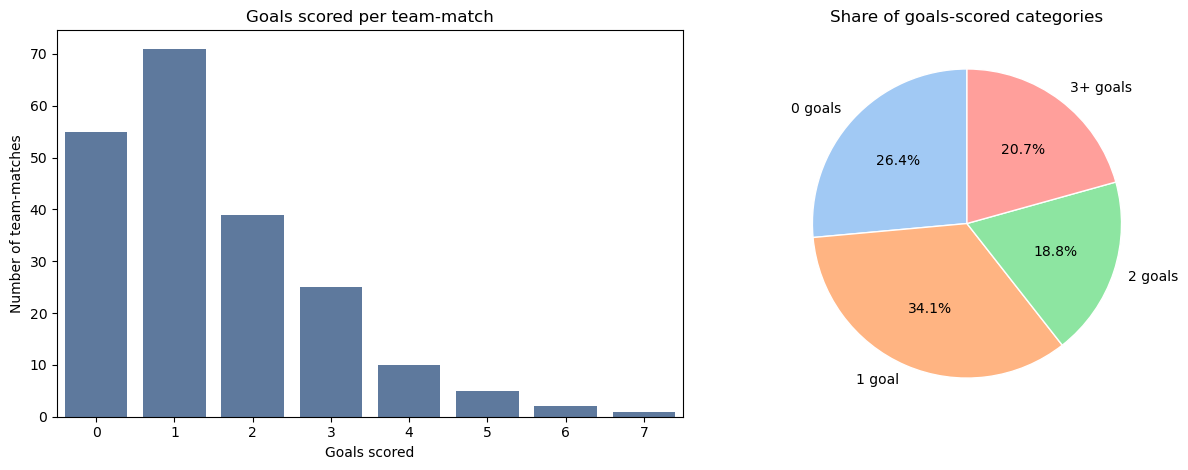

In [8]:
goals_summary = data['goals_scored'].value_counts().sort_index()
print('Goals scored per team-match:')
print(goals_summary)

eda = data.copy()
eda['goals_group'] = pd.cut(eda['goals_scored'], bins=[-1,0,1,2,100],labels=['0','1','2','3+'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.countplot(data=eda, x='goals_scored', order=sorted(eda['goals_scored'].unique()),color='#5378a8', ax=ax[0])
ax[0].set(title='Goals scored per team-match', xlabel='Goals scored', ylabel='Number of team-matches')
counts = eda['goals_group'].value_counts().reindex(['0','1','2','3+'])
ax[1].pie(counts, labels=['0 goals','1 goal','2 goals','3+ goals'],autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel', 4),wedgeprops={'edgecolor':'white'})
ax[1].set_title('Share of goals-scored categories')

plt.tight_layout()
plt.show()

`Intuition:` Team goal counts are concentrated around 0, 1 and 2 goals. This helps explain why the task can be difficult: football goals have a discrete, uneven distribution, whereas ordinary linear regression predicts continuous values. We still use linear regression because that is the algorithm required by the question.

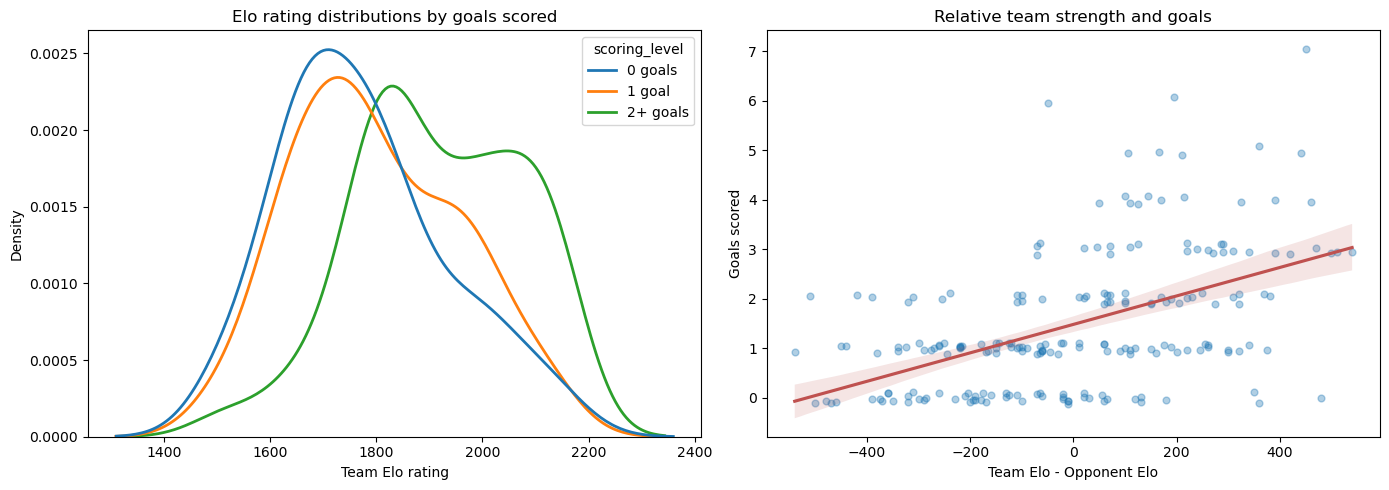

In [10]:
eda['scoring_level'] = pd.cut(eda['goals_scored'], [-1,0,1,100],
                               labels=['0 goals','1 goal','2+ goals'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=eda, x='team_elo', hue='scoring_level',common_norm=False, fill=False, linewidth=2, ax=ax[0])
ax[0].set(title='Elo rating distributions by goals scored', xlabel='Team Elo rating')

eda['elo_difference_for_plot'] = eda['team_elo'] - eda['opponent_elo']
sns.regplot(data=eda, x='elo_difference_for_plot', y='goals_scored',x_jitter=0, y_jitter=0.12, scatter_kws={'alpha':0.35,'s':24},line_kws={'color':'#bf514f'}, ax=ax[1])
ax[1].set(title='Relative team strength and goals',xlabel='Team Elo - Opponent Elo', ylabel='Goals scored')
plt.tight_layout()
plt.show()

`Observation:` Higher-rated teams tend to score more often, and the overall trend is positive when a team's Elo exceeds its opponent's. There is still considerable scatter, so Elo cannot explain every match outcome. The elo_difference_for_plot column is only an EDA aid; our regression continues to use exactly eight predictors.

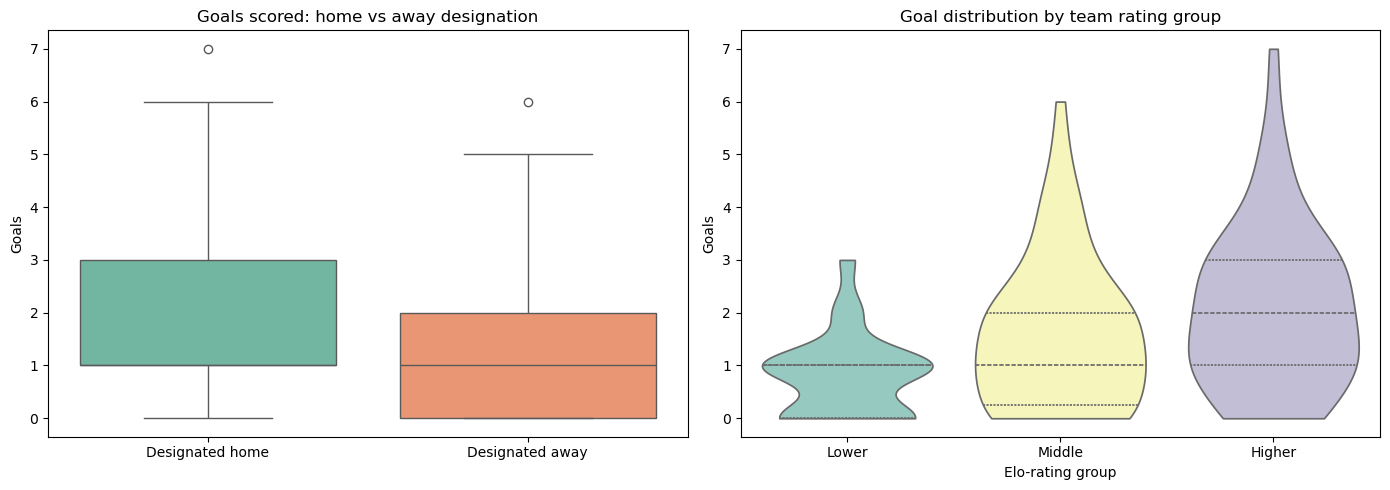

Mean goals by designated side:


,count,mean,median
home_status,,,
Designated away,104,1.24,1.0
Designated home,104,1.72,1.0


In [11]:
eda['home_status'] = eda['is_home'].map({1:'Designated home', 0:'Designated away'})
eda['elo_category'] = pd.qcut(eda['team_elo'], q=3, labels=['Lower','Middle','Higher'])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=eda, x='home_status', y='goals_scored', hue='home_status',palette='Set2', legend=False, ax=ax[0])
ax[0].set(title='Goals scored: home vs away designation', xlabel='', ylabel='Goals')
sns.violinplot(data=eda, x='elo_category', y='goals_scored', hue='elo_category',palette='Set3', inner='quartile', legend=False, cut=0, ax=ax[1])
ax[1].set(title='Goal distribution by team rating group',xlabel='Elo-rating group', ylabel='Goals')
plt.tight_layout()
plt.show()

print('Mean goals by designated side:')
display(eda.groupby('home_status')['goals_scored'].agg(['count','mean','median']).round(2))

`Interpretation:` The plots allow a comparison of both the typical score and the variability across groups. Being the designated home team is not the same as playing in one's own country, so any difference here should be described as an association, not automatically as a home-ground effect.

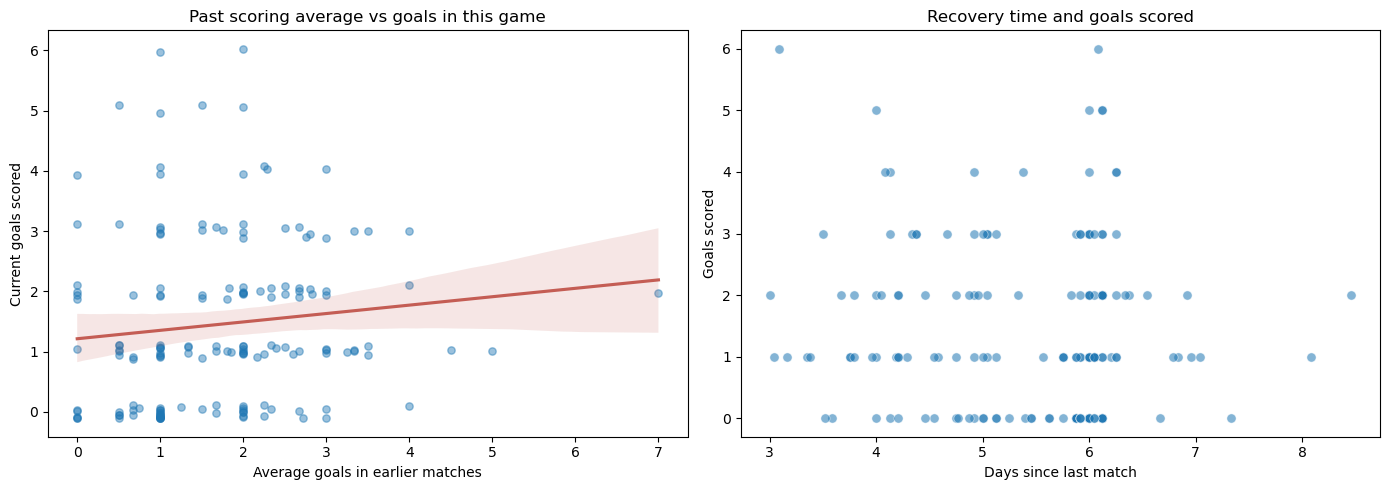

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=eda, x='prior_goals_scored', y='goals_scored',y_jitter=0.12, scatter_kws={'alpha':0.45,'s':28},line_kws={'color':'#c45d54'}, ax=ax[0])
ax[0].set(title='Past scoring average vs goals in this game',xlabel='Average goals in earlier matches', ylabel='Current goals scored')
sns.scatterplot(data=eda, x='days_rest', y='goals_scored',alpha=0.55, s=44, ax=ax[1])
ax[1].set(title='Recovery time and goals scored',xlabel='Days since last match', ylabel='Goals scored')

plt.tight_layout()
plt.show()

`Observation:` Both charts exclude the 48 first-match observations because they have no earlier tournament game. A team's past goal average may not perfectly predict its next score, and rest duration varies over a narrow range. This illustrates why multiple predictors are preferable to relying on a single statistic.

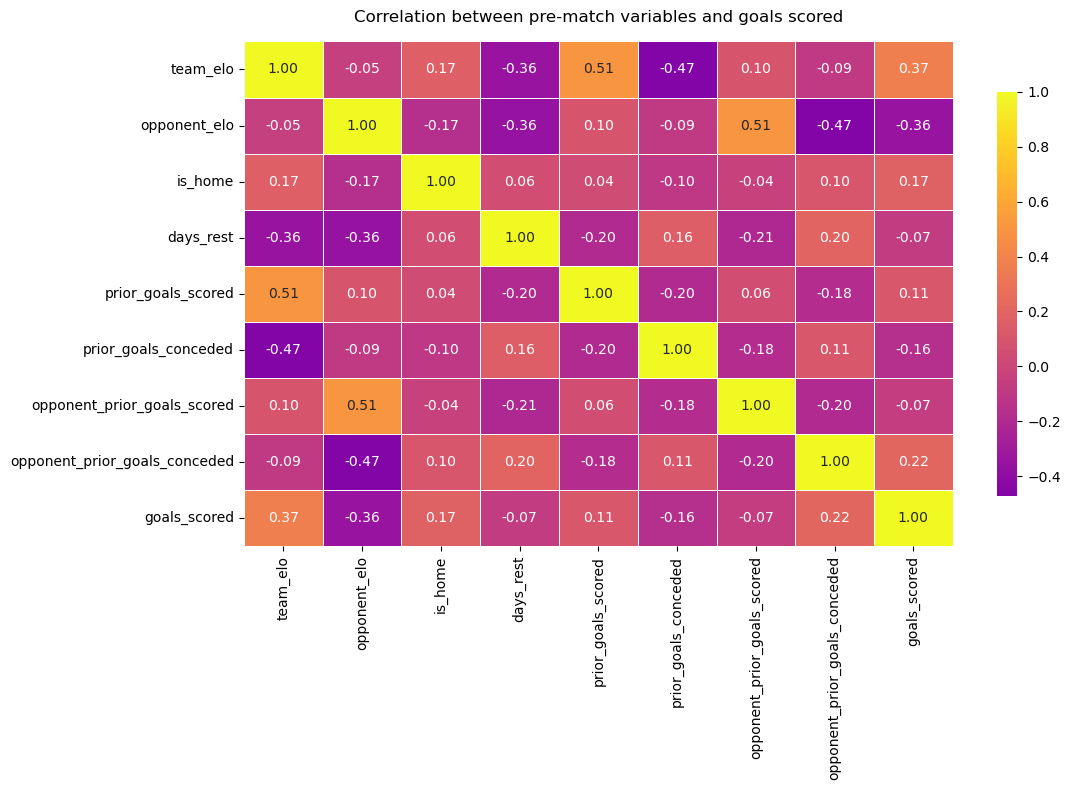

In [19]:
plt.figure(figsize=(11.5, 8))
corr = data[feature_cols + ['goals_scored']].corr()
sns.heatmap(corr, cmap='plasma', center=0, annot=True, fmt='.2f',linewidths=0.5, square=False, cbar_kws={'shrink':0.8})
plt.title('Correlation between pre-match variables and goals scored', pad=14)
plt.tight_layout()
plt.show()

## Data preprocessing and train-test split

In [20]:
X = data[feature_cols]
y = data['goals_scored']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=145)
train_idx, test_idx = next(splitter.split(X, y, groups=data['match_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print('Training team observations:', X_train.shape[0])
print('Testing team observations:', X_test.shape[0])
print('Training matches:', data.iloc[train_idx]['match_id'].nunique())
print('Testing matches:', data.iloc[test_idx]['match_id'].nunique())
print('Shared match IDs:', len(set(data.iloc[train_idx]['match_id']) &set(data.iloc[test_idx]['match_id'])))

model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('linear_regression', LinearRegression())
])
model.fit(X_train, y_train)
print('Linear regression model trained successfully.')

Training team observations: 166
Testing team observations: 42
Training matches: 83
Testing matches: 21
Shared match IDs: 0
Linear regression model trained successfully.


In [21]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)
train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
within_one = np.mean(np.abs(y_test - test_predictions) <= 1) * 100
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

results = pd.DataFrame({
    'Metric':['R2 (explained variance)','MAE (goals)','RMSE (goals)'],
    'Training':[train_r2, train_mae, train_rmse],
    'Testing':[test_r2, test_mae, test_rmse]
})
display(results.round(4))
print(f'Test R2 as a percentage of explained variance: {test_r2*100:.2f}%')
print(f'Test predictions within 1 goal: {within_one:.2f}%')
print(f'Test MAE from always predicting training mean: {baseline_mae:.3f} goals')

prediction_table = data.iloc[test_idx][['match_id','team_id','goals_scored']].copy()
prediction_table['predicted_goals'] = test_predictions
prediction_table['absolute_error'] = np.abs(prediction_table['goals_scored'] - prediction_table['predicted_goals'])
prediction_table.to_csv('linear_regression_2_2_ols_predictions.csv', index=False)

metrics_file = pd.DataFrame([{
    'train_r2':train_r2,'test_r2':test_r2,'train_mae':train_mae,
    'test_mae':test_mae,'train_rmse':train_rmse,'test_rmse':test_rmse,
    'within_1_goal_pct':within_one,'baseline_test_mae':baseline_mae
}])
metrics_file.to_csv('linear_regression_2_2_ols_metrics.csv', index=False)

print('Sample test predictions:')
display(prediction_table.head(10).round(2))

,Metric,Training,Testing
0,R2 (explained variance),0.2620,0.2422
1,MAE (goals),0.9133,0.8539
2,RMSE (goals),1.2210,1.0794


Test R2 as a percentage of explained variance: 24.22%
Test predictions within 1 goal: 69.05%
Test MAE from always predicting training mean: 1.076 goals
Sample test predictions:


,match_id,team_id,goals_scored,predicted_goals,absolute_error
0,1,1,2,2.18,0.18
1,1,2,0,0.95,0.95
2,2,3,2,1.78,0.22
3,2,4,1,1.29,0.29
48,25,1,1,1.61,0.61
49,25,3,0,1.36,1.36
60,31,13,2,1.65,0.35
61,31,15,0,1.56,1.56
68,35,21,5,2.26,2.74
69,35,23,1,0.95,0.05


`Interpretation:` R² should be described as explained variance, not the percentage of matches predicted correctly. MAE expresses the typical size of a prediction error in actual goals. The within-one-goal percentage offers an additional intuitive check but has a different meaning from R². Results are based only on the held-out test matches.

## Actual vs predicted goals

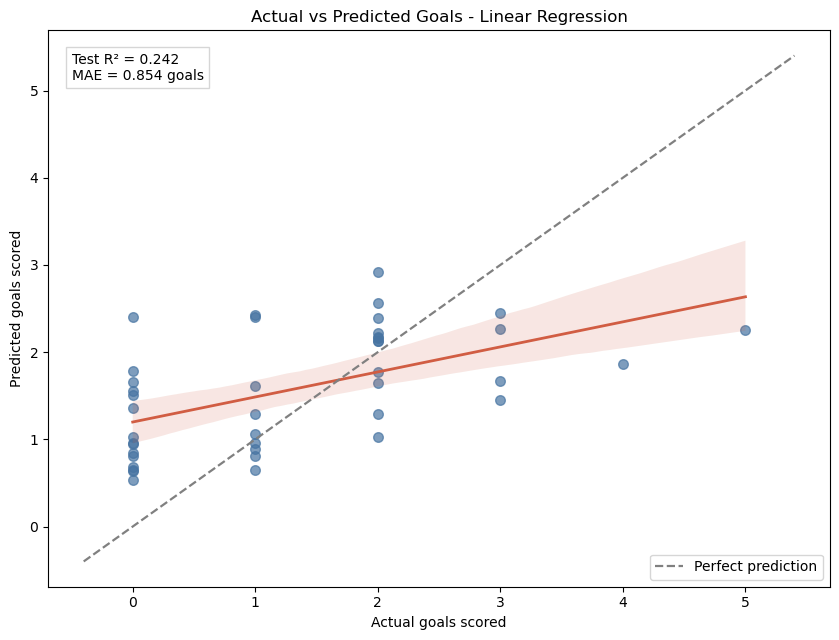

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.regplot(x=y_test.to_numpy(), y=test_predictions, ax=ax,scatter_kws={'s':48,'alpha':0.70,'color':'#4774a2'},line_kws={'color':'#d15d43','linewidth':2})

low = min(y_test.min(), test_predictions.min()) - 0.4
high = max(y_test.max(), test_predictions.max()) + 0.4

ax.plot([low, high], [low, high], linestyle='--', linewidth=1.6,color='gray', label='Perfect prediction')
ax.set(xlabel='Actual goals scored', ylabel='Predicted goals scored',title='Actual vs Predicted Goals - Linear Regression')
ax.text(0.03, 0.96, f'Test R² = {test_r2:.3f}\nMAE = {test_mae:.3f} goals',
        transform=ax.transAxes, va='top',
        bbox=dict(facecolor='white', edgecolor='lightgray', alpha=0.92))
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

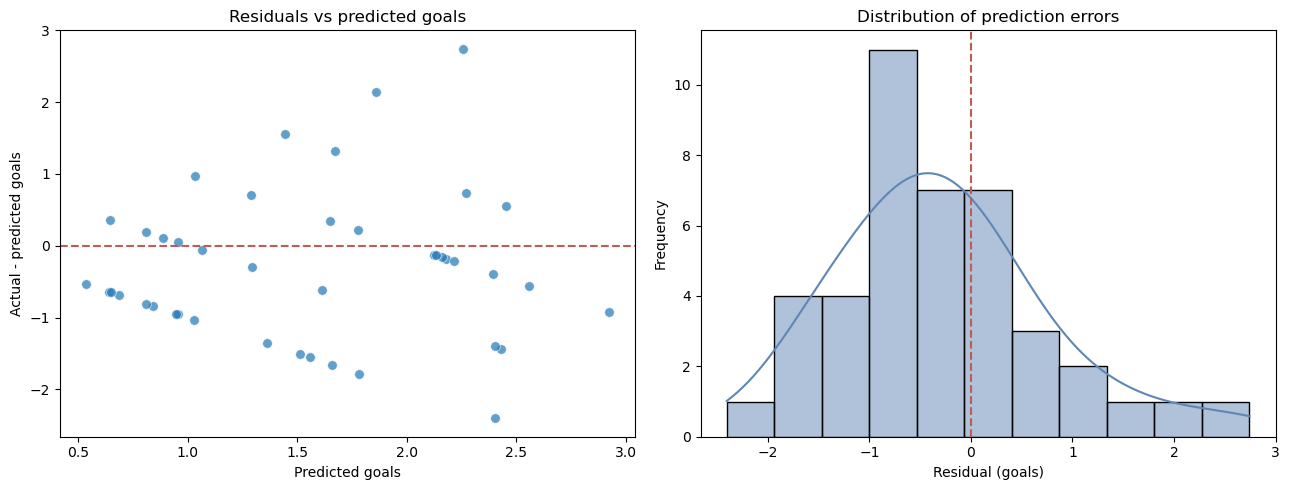

In [24]:
residuals = y_test.to_numpy() - test_predictions
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=test_predictions, y=residuals, ax=ax[0], s=48, alpha=0.7)

ax[0].axhline(0, linestyle='--', color='#c15c52')
ax[0].set(title='Residuals vs predicted goals', xlabel='Predicted goals',ylabel='Actual - predicted goals')
sns.histplot(residuals, bins=11, kde=True, color='#6086b4', ax=ax[1])
ax[1].axvline(0, linestyle='--', color='#c15c52')
ax[1].set(title='Distribution of prediction errors', xlabel='Residual (goals)',ylabel='Frequency')

plt.tight_layout()
plt.show()

`Observation:` Wide residuals indicate matches that are particularly difficult to predict, such as unexpected high-scoring games. As a regression model for nonnegative counts, an unrestricted linear regression can even return negative numbers for some combinations of features. We keep the original outputs for honest evaluation rather than quietly altering them.

## Cross-validation

In [25]:
cross_validation = GroupKFold(n_splits=5)
train_groups = data.iloc[train_idx]['match_id']
folds = cross_validation.split(X_train, y_train, groups=train_groups)
cv_r2 = cross_val_score(model, X_train, y_train, cv=folds, scoring='r2')
folds = cross_validation.split(X_train, y_train, groups=train_groups)
cv_mae = -cross_val_score(model, X_train, y_train, cv=folds,scoring='neg_mean_absolute_error')

print('Cross-validation R² by fold:', np.round(cv_r2, 3))
print('Mean cross-validation R²:', round(cv_r2.mean(), 3))
print('Mean cross-validation MAE:', round(cv_mae.mean(), 3), 'goals')

Cross-validation R² by fold: [-0.033  0.223  0.068  0.254  0.225]
Mean cross-validation R²: 0.147
Mean cross-validation MAE: 0.966 goals
